In [1]:
import sys, os

root = os.path.abspath("..")
os.chdir(root)                     
if root not in sys.path:
    sys.path.insert(0, root)

print(os.getcwd())                

import pandas as pd 
import matplotlib.pyplot as plt


c:\Users\CSITOCT\Desktop\object_detection


<br>

# `#01: Precision By Score Analysis`

**No faces but model detected**

<br>

In [2]:
import pandas as pd
import warnings 

warnings.filterwarnings("ignore")

ROOT = r"C:\Users\CSITOCT\Desktop\object_detection"
pbs = pd.read_csv(rf"{ROOT}\outputs\precision_by_score.csv", encoding="utf-8")
pbs.drop_duplicates(subset=["tag", "score_thr"], keep="last", inplace=True)
res = pd.read_csv(rf"{ROOT}\results.csv", encoding="utf-8")
res.drop_duplicates(subset=["tag"], keep="last", inplace=True)

# ---- 1. AP from results.csv (column names found automatically) ----
def col(df, word):
    return [c for c in df.columns if word in c.lower()][0]
tag_c, e_c, m_c, h_c = col(res, "tag"), col(res, "easy"), col(res, "medium"), col(res, "hard")
ap = (res.drop_duplicates(tag_c, keep="last")
         .rename(columns={tag_c: "tag", e_c: "easy", m_c: "medium", h_c: "hard"})
         [["tag", "easy", "medium", "hard"]])

# ---- 2. choose what to compare (same seed only!) ----
SEED = "seed0"
pbs = pbs.drop_duplicates(["tag", "score_thr"], keep="last")
keep = pbs.tag.str.endswith(SEED) | pbs.tag.str.startswith("released")
pbs = pbs[keep]

# ---- 3. one row per model at a working threshold (0.5) ----
THR = 0.5
op = (pbs[pbs.score_thr == THR]
        [["tag", "hits", "false_alarms", "precision", "false_alarms_per_image"]]
        .merge(ap, on="tag", how="left"))

# ---- 4. Pareto: is there another model with more hits AND fewer false alarms? ----
def beaten_by(r):
    better = op[(op.hits >= r.hits) & (op.false_alarms <= r.false_alarms) &
                ((op.hits > r.hits) | (op.false_alarms < r.false_alarms))]
    return ", ".join(better.tag) if len(better) else ""
op["beaten_by"] = [beaten_by(r) for r in op.itertuples()]
op["pareto_best"] = op.beaten_by == ""

# ---- 5. show as DataFrames ----
from IPython.display import display

cols = ["tag", "hard", "medium", "easy", "hits", "false_alarms_per_image", "precision", "pareto_best", "beaten_by"]
best = (op.sort_values("hard", ascending=False)[cols]
          .reset_index(drop=True)
          .rename(columns={"false_alarms_per_image": "false/img"}))
best.index = best.index + 1                     # rank starts at 1
best.index.name = "rank"

print(f"{SEED}, score >= {THR}, sorted by Hard AP")
display(best.style
        .format({"hard": "{:.2f}", "medium": "{:.2f}", "easy": "{:.2f}",
                 "false/img": "{:.3f}", "precision": "{:.3f}"})
        .highlight_max(subset=["hard", "medium", "easy", "hits", "precision"], color="#116321")
        .highlight_min(subset=["false/img"], color="#59254D"))

#
# ########################################### Here, come another qustion ###########################################
#
# Here, false/img rate low does not menas that our model is better. We think maybe
# using loop drease false/img rate, but it will also decrease hits. So, we need to test that 
# is the model remove this where there exist face or remove those where there is no face but model predicts face. 
#
#

seed0, score >= 0.5, sorted by Hard AP


,tag,hard,medium,easy,hits,false/img,precision,pareto_best,beaten_by
rank,,,,,,,,,
1,released_mnet_L0,0.74,0.88,0.91,19881,0.989,0.862,True,
2,cfg_mnet_loopcnn_ssh_L0_seed0,0.70,0.85,0.87,18408,0.824,0.874,True,
3,cfg_mnet_haar_loop_L1_seed0,0.70,0.86,0.89,19082,1.175,0.834,False,released_mnet_L0
4,cfg_mnet_loop_L2_seed0,0.70,0.87,0.89,18217,0.869,0.867,False,cfg_mnet_loopcnn_ssh_L0_seed0
5,cfg_mnet_haar_loop_L2_seed0,0.70,0.86,0.89,18672,1.086,0.842,False,"cfg_mnet_haar_loop_L12_seed0, cfg_mnet_haar_loop_L16_seed0, released_mnet_L0"
6,cfg_mnet_loop_L12_seed0,0.70,0.87,0.89,18019,0.809,0.873,True,
7,cfg_mnet_loop_L8_seed0,0.70,0.87,0.89,18017,0.810,0.873,False,cfg_mnet_loop_L12_seed0
8,cfg_mnet_loop_L16_seed0,0.70,0.87,0.89,18016,0.810,0.873,False,"cfg_mnet_loop_L8_seed0, cfg_mnet_loop_L12_seed0"
9,cfg_mnet_loop_L4_seed0,0.70,0.87,0.89,17972,0.806,0.874,True,


In [3]:


import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

ROOT = r"C:\Users\CSITOCT\Desktop\object_detection"
fa  = pd.read_csv(rf"{ROOT}\outputs\false_alarm_types.csv").drop_duplicates(["tag", "score_thr", "iou_thr"], keep="last")
ss  = pd.read_csv(rf"{ROOT}\outputs\score_separation.csv").drop_duplicates(["tag", "min_score", "iou_thr"], keep="last")
hs  = pd.read_csv(rf"{ROOT}\outputs\score_hist.csv").drop_duplicates(["tag", "bin_lo"], keep="last")
res = pd.read_csv(rf"{ROOT}\results.csv").drop_duplicates("tag", keep="last")
ap  = res[["tag", "easy", "medium", "hard"]].copy()
ap[["easy", "medium", "hard"]] *= 100                      # AP in %

SEED = "seed0"                  # compare within one seed
THR  = 0.5                      # score threshold for false alarm types (0.3 or 0.5)
REF  = "cfg_mnet_L0_seed0"      # reference model for the "change" table

def pick(df):
    return df[df.tag.str.endswith(SEED) | df.tag.str.startswith("released")]

GOOD, BAD = "#116321", "#59254D"   # your highlight colours
print("models in false_alarm_types:", pick(fa).tag.nunique(), "| in score_separation:", pick(ss).tag.nunique())


models in false_alarm_types: 47 | in score_separation: 47


In [4]:
f = pick(fa[np.isclose(fa.score_thr, THR)]).copy()
f["false_per100"] = f[["dup_per100", "loc_per100", "bg_per100"]].sum(axis=1)
f["precision"] = f.tp / (f.tp + f.dup + f["loc"] + f.bg)
f["bg_share"] = f.bg_per100 / f.false_per100 * 100          # % of the false alarms that are background

t1 = f.merge(ap, on="tag", how="left").sort_values("hard", ascending=False).reset_index(drop=True)
t1.index = t1.index + 1
t1.index.name = "rank"

names = {"tp_per100": "tp/100", "false_per100": "false/100", "dup_per100": "dup/100",
         "loc_per100": "loc/100", "bg_per100": "bg/100", "bg_share": "bg % of false"}
cols = ["tag", "hard", "medium", "easy", "tp_per100", "false_per100",
        "dup_per100", "loc_per100", "bg_per100", "bg_share", "precision"]
show = t1[cols].rename(columns=names)

print(f"False alarm types, {SEED}, score >= {THR}, per 100 images, sorted by Hard AP")
display(show.style
        .format({"hard": "{:.2f}", "medium": "{:.2f}", "easy": "{:.2f}", "tp/100": "{:.1f}", "false/100": "{:.1f}",
                 "dup/100": "{:.1f}", "loc/100": "{:.1f}", "bg/100": "{:.1f}", "bg % of false": "{:.0f}%",
                 "precision": "{:.3f}"})
        .highlight_max(subset=["hard", "medium", "easy", "tp/100", "precision"], color=GOOD)
        .highlight_min(subset=["false/100", "dup/100", "loc/100", "bg/100"], color=BAD))

# ---- change against the reference model (green = better: more hits / fewer false alarms) ----
if REF in set(t1.tag):
    num = ["tp_per100", "dup_per100", "loc_per100", "bg_per100", "false_per100"]
    base = t1.set_index("tag").loc[REF, num]
    d = (t1.set_index("tag")[num] - base).drop(index=REF)
    d = d.join(t1.set_index("tag")["hard"]).sort_values("hard", ascending=False).reset_index()
    d.index = d.index + 1
    d.index.name = "rank"
    d = d.rename(columns=names)
    fcols = ["dup/100", "loc/100", "bg/100", "false/100"]
    print(f"\nChange against {REF} (boxes per 100 images)")
    display(d[["tag", "hard", "tp/100"] + fcols].style
            .format({c: "{:+.1f}" for c in ["tp/100"] + fcols} | {"hard": "{:.2f}"})
            .background_gradient(subset=["tp/100"], cmap="RdYlGn", vmin=-40, vmax=40)
            .background_gradient(subset=fcols, cmap="RdYlGn_r", vmin=-40, vmax=40))
else:
    print(f"\n{REF} is not in false_alarm_types.csv; set REF to another tag")
#
#
# In, wider val total image: 3,226 faces ->  39,708 
# In 100 images we have -> 1230 faces. 
# tp/100 -> from 1230 faces in 10 images model detect: 616
# fasle/100 ->  make false 99.2 boxes 
# dup/100  -> duplicated boxes. (atmost get 1 box)
# loc /100 -> there have a face but box is not good (Iout < 0.5)
# bg/100 -> no. of box where ther is no faces. 
# 
# 
# 


False alarm types, seed0, score >= 0.5, per 100 images, sorted by Hard AP


,tag,hard,medium,easy,tp/100,false/100,dup/100,loc/100,bg/100,bg % of false,precision
rank,,,,,,,,,,,
1,released_mnet_L0,73.70,88.16,90.70,616.0,99.2,0.3,49.8,49.1,50%,0.861
2,cfg_mnet_loopcnn_ssh_L0_seed0,70.27,85.45,87.43,569.7,83.2,0.9,44.6,37.7,45%,0.873
3,cfg_mnet_haar_loop_L1_seed0,70.18,86.40,89.24,591.2,117.9,0.3,56.8,60.7,52%,0.834
4,cfg_mnet_loop_L2_seed0,70.05,86.60,89.02,564.3,87.4,0.4,44.5,42.4,49%,0.866
5,cfg_mnet_haar_loop_L2_seed0,69.99,86.45,89.08,578.4,109.0,0.4,54.1,54.5,50%,0.841
6,cfg_mnet_loop_L12_seed0,69.96,86.74,89.22,558.2,81.2,0.3,41.6,39.3,48%,0.873
7,cfg_mnet_loop_L8_seed0,69.96,86.72,89.20,558.2,81.2,0.2,41.7,39.3,48%,0.873
8,cfg_mnet_loop_L16_seed0,69.95,86.72,89.19,558.2,81.3,0.3,41.7,39.3,48%,0.873
9,cfg_mnet_loop_L4_seed0,69.91,86.68,89.07,556.9,80.8,0.2,41.5,39.0,48%,0.873



Change against cfg_mnet_L0_seed0 (boxes per 100 images)


,tag,hard,tp/100,dup/100,loc/100,bg/100,false/100
rank,,,,,,,
1,released_mnet_L0,73.70,+37.9,+0.0,-3.0,-3.8,-6.8
2,cfg_mnet_loopcnn_ssh_L0_seed0,70.27,-8.3,+0.6,-8.1,-15.2,-22.8
3,cfg_mnet_haar_loop_L1_seed0,70.18,+13.1,+0.0,+4.1,+7.8,+11.9
4,cfg_mnet_loop_L2_seed0,70.05,-13.8,+0.1,-8.2,-10.5,-18.6
5,cfg_mnet_haar_loop_L2_seed0,69.99,+0.4,+0.1,+1.3,+1.6,+3.0
6,cfg_mnet_loop_L12_seed0,69.96,-19.8,+0.0,-11.2,-13.6,-24.7
7,cfg_mnet_loop_L8_seed0,69.96,-19.8,-0.1,-11.1,-13.6,-24.7
8,cfg_mnet_loop_L16_seed0,69.95,-19.9,+0.0,-11.1,-13.6,-24.7
9,cfg_mnet_loop_L4_seed0,69.91,-21.2,-0.1,-11.2,-13.9,-25.2


In [5]:

s = pick(ss).copy()
s["gap"] = s.tp_mean - s.false_mean                          # how far apart the mean scores are
t2 = s.merge(ap, on="tag", how="left").sort_values("hard", ascending=False).reset_index(drop=True)
t2.index = t2.index + 1
t2.index.name = "rank"

cols = ["tag", "hard", "auroc", "tp_mean", "false_mean", "gap", "n_tp", "n_false"]
print(f"Score separation, {SEED}, all boxes with score >= {s.min_score.iloc[0]}, sorted by Hard AP")
display(t2[cols].style
        .format({"hard": "{:.2f}", "auroc": "{:.4f}", "tp_mean": "{:.3f}", "false_mean": "{:.3f}",
                 "gap": "{:.3f}", "n_tp": "{:,.0f}", "n_false": "{:,.0f}"})
        .highlight_max(subset=["hard", "auroc", "tp_mean", "gap", "n_tp"], color=GOOD)
        .highlight_min(subset=["false_mean", "n_false"], color=BAD))

#
#
# n_tp: number of correct box .  (based on confidence score with threshold )
# n_fasle: number of false box. (based on confidence score with threshold )
#
# tp_mean: for every n_tp will modle will give a confidence score.(mean of all confidence score for n_tp)
# false_mean: similary, tp_mean
# 
# tp_mean (big)  - false_mean(small) = gap(big) => model is good. 
#
#
# auroc: If we take two boxes: which give more probability that there is a face.
# 
#


Score separation, seed0, all boxes with score >= 0.02, sorted by Hard AP


,tag,hard,auroc,tp_mean,false_mean,gap,n_tp,n_false
rank,,,,,,,,
1,released_mnet_L0,73.70,0.9484,0.700,0.070,0.630,"28,036","218,814"
2,cfg_mnet_loopcnn_ssh_L0_seed0,70.27,0.9526,0.672,0.060,0.611,"27,426","309,122"
3,cfg_mnet_haar_loop_L1_seed0,70.18,0.9568,0.693,0.062,0.631,"27,270","384,887"
4,cfg_mnet_loop_L2_seed0,70.05,0.9507,0.669,0.064,0.605,"27,129","291,560"
5,cfg_mnet_haar_loop_L2_seed0,69.99,0.9534,0.681,0.065,0.616,"27,200","351,244"
6,cfg_mnet_loop_L12_seed0,69.96,0.9500,0.663,0.064,0.599,"27,099","285,713"
7,cfg_mnet_loop_L8_seed0,69.96,0.9502,0.663,0.064,0.599,"27,092","286,249"
8,cfg_mnet_loop_L16_seed0,69.95,0.9501,0.663,0.064,0.599,"27,097","285,677"
9,cfg_mnet_loop_L4_seed0,69.91,0.9503,0.662,0.063,0.598,"27,127","291,692"


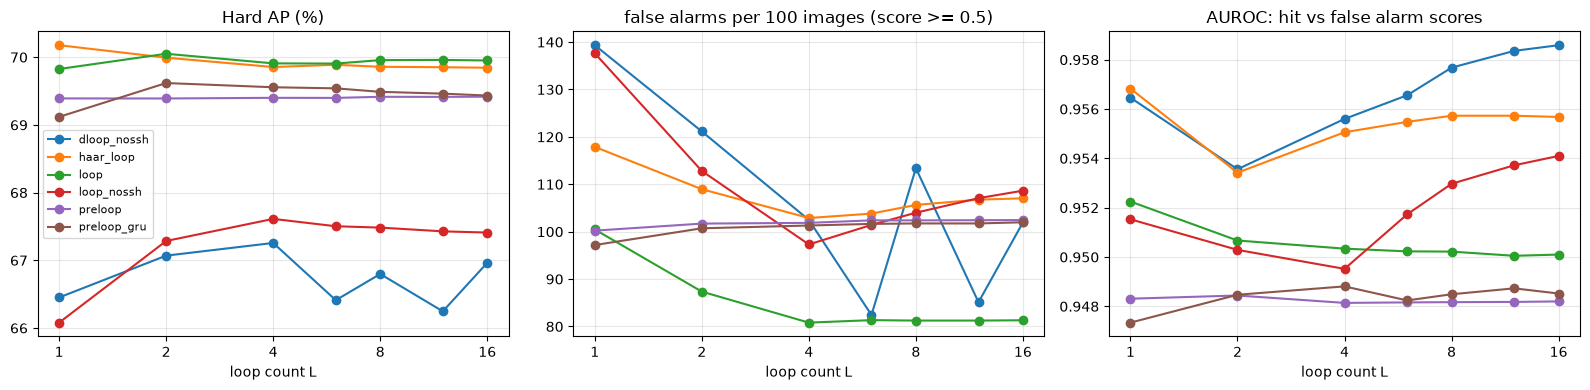

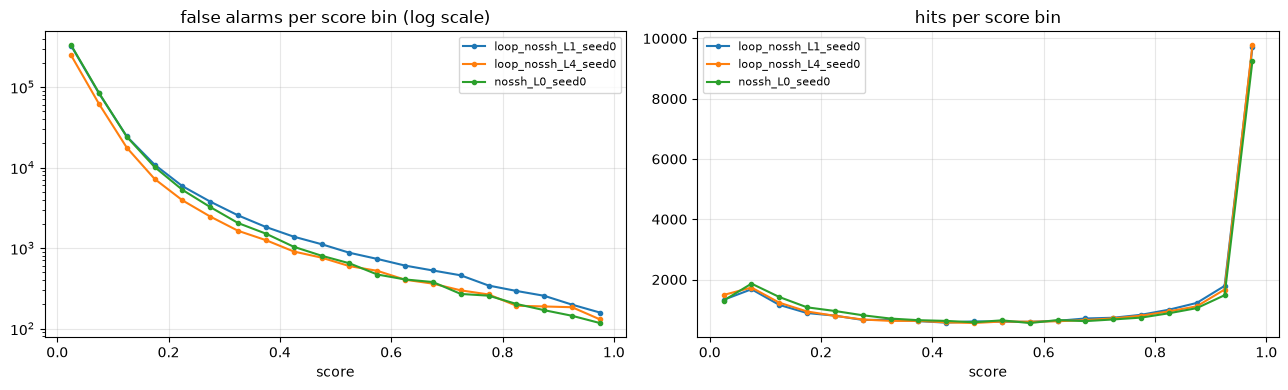

In [6]:
# ---- figure 1: everything against the loop count L (one line per loop model) ----
def split_tag(tag):
    m = re.match(r"^(.+)_L(\d+)_(seed\d+)$", tag)
    return (m.group(1), int(m.group(2))) if m else (tag, 0)

sweep = t1[["tag", "hard", "false_per100", "bg_per100"]].merge(t2[["tag", "auroc"]], on="tag", how="outer")
sweep[["cfg", "L"]] = sweep.tag.apply(lambda t: pd.Series(split_tag(t)))
sweep = sweep[sweep.L > 0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for cfg, g in sweep.groupby("cfg"):
    g = g.sort_values("L")
    if len(g) < 2:
        continue
    for ax, col in zip(axes, ["hard", "false_per100", "auroc"]):
        gg = g.dropna(subset=[col])
        ax.plot(gg.L, gg[col], marker="o", label=cfg.replace("cfg_mnet_", ""))
titles = ["Hard AP (%)", f"false alarms per 100 images (score >= {THR})", "AUROC: hit vs false alarm scores"]
for ax, title in zip(axes, titles):
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8, 16])
    ax.set_xticklabels([1, 2, 4, 8, 16])
    ax.set_xlabel("loop count L")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- figure 2: score histogram of false alarms and hits, for a few models ----
TAGS = ["cfg_mnet_loop_nossh_L1_seed0", "cfg_mnet_loop_nossh_L4_seed0", "cfg_mnet_nossh_L0_seed0"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for tag in TAGS:
    h = hs[hs.tag == tag].sort_values("bin_lo")
    if h.empty:
        print("not in score_hist.csv:", tag)
        continue
    mid = (h.bin_lo + h.bin_hi) / 2
    axes[0].plot(mid, h.n_false, marker=".", label=tag.replace("cfg_mnet_", ""))
    axes[1].plot(mid, h.n_tp, marker=".", label=tag.replace("cfg_mnet_", ""))
axes[0].set_yscale("log")
axes[0].set_title("false alarms per score bin (log scale)")
axes[1].set_title("hits per score bin")
for ax in axes:
    ax.set_xlabel("score")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# save both for the paper:  fig.savefig(rf"{ROOT}\outputs\score_hist.pdf", bbox_inches="tight")

<br>

# `#02: Recall-by-size`

**No faces but model detected. It's hurt the AP.**

<br>

In [7]:

import warnings
import numpy as np 
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")

ROOT = r"C:\Users\CSITOCT\Desktop\object_detection"
rbs = pd.read_csv(rf"{ROOT}\outputs\recall_by_size.csv", encoding="utf-8")
rbs.drop_duplicates(subset=["tag", "size_lo", "score_thr", "iou_thr"], keep="last", inplace=True)
res = pd.read_csv(rf"{ROOT}\results.csv", encoding="utf-8")
res.drop_duplicates(subset=["tag"], keep="last", inplace=True)

# ---- 1. AP from results.csv (in %) ----
ap = res[["tag", "easy", "medium", "hard"]].copy()
ap[["easy", "medium", "hard"]] *= 100

# ---- 2. choose what to compare ----
SEED = "seed0"                 # same seed only
THR  = 0.02                    # score threshold: 0.02, 0.3 or 0.5
IOU  = 0.5
REF  = "cfg_mnet_L0_seed0"        # reference model for the "gain" table

r = rbs[np.isclose(rbs.score_thr, THR) & np.isclose(rbs.iou_thr, IOU)]
r = r[r.tag.str.endswith(SEED) | r.tag.str.startswith("released")].copy()
if r.empty:
    raise ValueError(f"no rows for score_thr={THR}, iou_thr={IOU}, {SEED}. "
                     f"available score_thr: {sorted(rbs.score_thr.unique())}")

# ---- 3. size bin labels, in size order ----
r["size"] = r.size_lo.map(lambda v: f"{v:g}") + "-" + r.size_hi.astype(str) + " px"
order = r.drop_duplicates("size").sort_values("size_lo")["size"].tolist()
n_gt  = r.drop_duplicates("size").set_index("size").loc[order, "n_gt"]

# ---- 4. one row per model: recall in every size bin + overall recall ----
wide = r.pivot_table(index="tag", columns="size", values="recall")[order]
wide["all sizes"] = (wide[order] * n_gt.values).sum(axis=1) / n_gt.sum()   # weighted by number of faces
table = wide.reset_index().merge(ap, on="tag", how="left")
table = table.sort_values("hard", ascending=False).reset_index(drop=True)
table.index = table.index + 1
table.index.name = "rank"

print(f"{SEED}, recall at score >= {THR}, IoU >= {IOU}, sorted by Hard AP")
print("faces per size bin:", dict(zip(order, n_gt.astype(int))))
rec_cols = order + ["all sizes"]
display(table[["tag", "hard", "medium", "easy"] + rec_cols].style
        .format({c: "{:.3f}" for c in rec_cols} | {"hard": "{:.2f}", "medium": "{:.2f}", "easy": "{:.2f}"})
        .highlight_max(subset=["hard", "medium", "easy"] + rec_cols, color="#116321"))

# ---- 5. gain over the reference model, per size (in recall points, x100) ----
if REF in wide.index:
    gain = (wide[rec_cols] - wide.loc[REF, rec_cols]) * 100
    gain = gain.drop(index=REF).reset_index().merge(ap[["tag", "hard"]], on="tag", how="left")
    gain = gain.sort_values("hard", ascending=False).reset_index(drop=True)
    gain.index = gain.index + 1
    gain.index.name = "rank"
    print(f"\nrecall gain over {REF} (percentage points; green = finds more, red = finds fewer)")
    display(gain[["tag", "hard"] + rec_cols].style
            .format({c: "{:+.1f}" for c in rec_cols} | {"hard": "{:.2f}"})
            .background_gradient(subset=rec_cols, cmap="RdYlGn", vmin=-5, vmax=5))
else:
    print(f"\n{REF} not in recall_by_size.csv at score {THR}; set REF to another tag")

#
# 
#  Chagne the theshold value: see the effect on: 
#  For theshold value: 0.5 it's show that small size face vinished after loop increases.
#  But, 0.02 threshold, it's show every thing is good. (loop does not heart the small size face detection)
#
#


seed0, recall at score >= 0.02, IoU >= 0.5, sorted by Hard AP
faces per size bin: {'0-8.0 px': 6061, '8-16.0 px': 12446, '16-32.0 px': 10268, '32-64.0 px': 6650, '64-inf px': 4283}


,tag,hard,medium,easy,0-8.0 px,8-16.0 px,16-32.0 px,32-64.0 px,64-inf px,all sizes
rank,,,,,,,,,,
1,released_mnet_L0,73.70,88.16,90.70,0.141,0.639,0.860,0.940,0.972,0.706
2,cfg_mnet_loopcnn_ssh_L0_seed0,70.27,85.45,87.43,0.108,0.614,0.856,0.933,0.968,0.691
3,cfg_mnet_haar_loop_L1_seed0,70.18,86.40,89.24,0.102,0.599,0.858,0.939,0.971,0.687
4,cfg_mnet_loop_L2_seed0,70.05,86.60,89.02,0.102,0.599,0.849,0.935,0.964,0.684
5,cfg_mnet_haar_loop_L2_seed0,69.99,86.45,89.08,0.093,0.598,0.858,0.940,0.968,0.685
6,cfg_mnet_loop_L12_seed0,69.96,86.74,89.22,0.107,0.595,0.847,0.935,0.966,0.683
7,cfg_mnet_loop_L8_seed0,69.96,86.72,89.20,0.106,0.595,0.848,0.935,0.965,0.683
8,cfg_mnet_loop_L16_seed0,69.95,86.72,89.19,0.107,0.595,0.847,0.935,0.965,0.683
9,cfg_mnet_loop_L4_seed0,69.91,86.68,89.07,0.104,0.598,0.849,0.936,0.965,0.683



recall gain over cfg_mnet_L0_seed0 (percentage points; green = finds more, red = finds fewer)


,tag,hard,0-8.0 px,8-16.0 px,16-32.0 px,32-64.0 px,64-inf px,all sizes
rank,,,,,,,,
1,released_mnet_L0,73.70,+4.1,+3.2,+1.4,+0.2,+0.1,+2.0
2,cfg_mnet_loopcnn_ssh_L0_seed0,70.27,+0.7,+0.7,+1.0,-0.6,-0.2,+0.5
3,cfg_mnet_haar_loop_L1_seed0,70.18,+0.1,-0.8,+1.2,+0.0,-0.0,+0.1
4,cfg_mnet_loop_L2_seed0,70.05,+0.2,-0.8,+0.3,-0.3,-0.7,-0.3
5,cfg_mnet_haar_loop_L2_seed0,69.99,-0.8,-1.0,+1.2,+0.1,-0.2,-0.1
6,cfg_mnet_loop_L12_seed0,69.96,+0.7,-1.2,+0.1,-0.3,-0.5,-0.4
7,cfg_mnet_loop_L8_seed0,69.96,+0.6,-1.2,+0.2,-0.3,-0.5,-0.4
8,cfg_mnet_loop_L16_seed0,69.95,+0.7,-1.2,+0.1,-0.3,-0.5,-0.4
9,cfg_mnet_loop_L4_seed0,69.91,+0.4,-0.9,+0.3,-0.2,-0.6,-0.3


<br>

# `#03: Benchmark -> GMACs(params,ms)`

<br>

,config,L,params,gmac,ms_median,hard
0,cfg_mnet_dloop_nossh,1,359345,1.000,25.607,66.451
1,cfg_mnet_dloop_nossh,2,359345,1.310,29.866,67.069
2,cfg_mnet_dloop_nossh,4,359345,1.930,39.012,67.257
3,cfg_mnet_dloop_nossh,8,359345,3.168,55.504,66.798
4,cfg_mnet_dloop_nossh,16,359345,5.645,88.380,66.964
5,cfg_mnet_haar_loop,1,475073,1.430,40.300,70.177
6,cfg_mnet_haar_loop,2,475073,1.740,44.148,69.993
7,cfg_mnet_haar_loop,4,475073,2.359,53.541,69.855
8,cfg_mnet_haar_loop,8,475073,3.598,70.315,69.858
9,cfg_mnet_haar_loop,16,475073,6.075,103.895,69.844


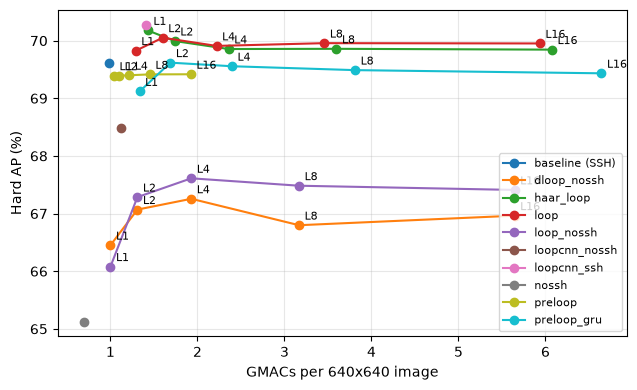

In [8]:


import pandas as pd
import matplotlib.pyplot as plt

# ---- AP vs compute: one loop model, many budgets ----
bm = pd.read_csv(rf"{ROOT}\outputs\benchmark.csv").drop_duplicates(["config", "L", "device", "threads", "size"], keep="last")
bm["tag"] = bm.config + "_L" + bm.L.astype(str) + "_seed0"
d = bm[bm.device == "cpu"].merge(ap, on="tag", how="inner")
display(d[["config", "L", "params", "gmac", "ms_median", "hard"]].round(3))

fig, ax = plt.subplots(figsize=(6.5, 4))
for cfg, g in d.groupby("config"):
    g = g.sort_values("gmac")
    ax.plot(g.gmac, g.hard, marker="o", label=cfg.replace("cfg_mnet_", "") if cfg != "cfg_mnet" else "baseline (SSH)")
    for _, r in g[g.L > 0].iterrows():
        ax.annotate(f"L{r.L}", (r.gmac, r.hard), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("GMACs per 640x640 image"); ax.set_ylabel("Hard AP (%)")
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()




                 config   L  params    gmac  ms_median   ms_p90 device  \
0  cfg_mnet_dloop_nossh   1  359345  1.0005     25.607   27.289    cpu   
1  cfg_mnet_dloop_nossh   2  359345  1.3102     29.866   32.918    cpu   
2  cfg_mnet_dloop_nossh   4  359345  1.9295     39.012   41.130    cpu   
3  cfg_mnet_dloop_nossh   8  359345  3.1681     55.504   58.600    cpu   
4  cfg_mnet_dloop_nossh  16  359345  5.6454     88.380   91.219    cpu   
5    cfg_mnet_haar_loop   1  475073  1.4301     40.300   43.430    cpu   
6    cfg_mnet_haar_loop   2  475073  1.7397     44.148   46.680    cpu   
7    cfg_mnet_haar_loop   4  475073  2.3590     53.541   56.359    cpu   
8    cfg_mnet_haar_loop   8  475073  3.5977     70.315   73.326    cpu   
9    cfg_mnet_haar_loop  16  475073  6.0749    103.895  108.350    cpu   

   threads  size  
0        1   640  
1        1   640  
2        1   640  
3        1   640  
4        1   640  
5        1   640  
6        1   640  
7        1   640  
8        1   6

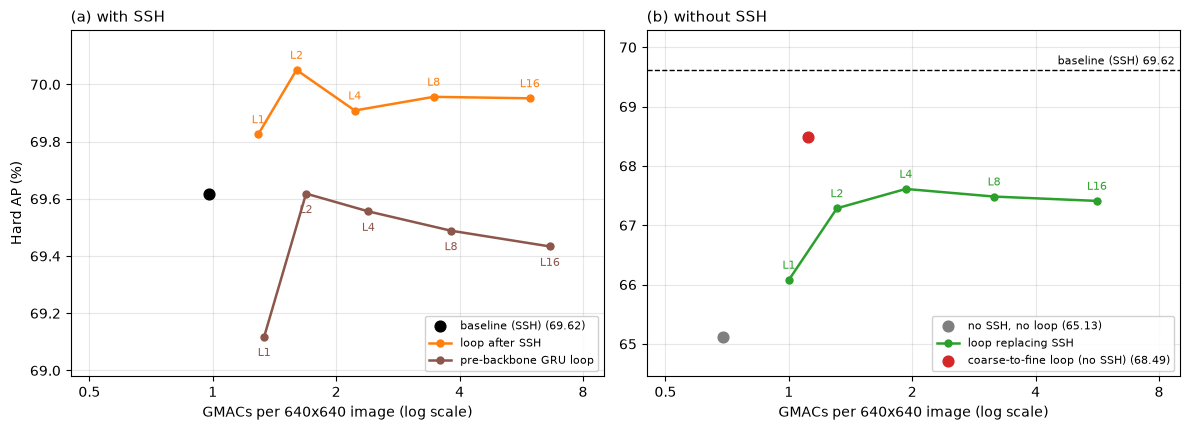

In [9]:
from matplotlib.ticker import FixedLocator, FixedFormatter

# ---------- names and colours: the same model has the same colour in every figure ----------
NAME = {"cfg_mnet": "baseline (SSH)", "cfg_mnet_loop": "loop after SSH",
        "cfg_mnet_preloop_gru": "pre-backbone GRU loop", "cfg_mnet_nossh": "no SSH, no loop",
        "cfg_mnet_loop_nossh": "loop replacing SSH", "cfg_mnet_loopcnn_nossh": "coarse-to-fine loop (no SSH)"}
COLOR = {"cfg_mnet": "black", "cfg_mnet_loop": "tab:orange", "cfg_mnet_preloop_gru": "tab:brown",
         "cfg_mnet_nossh": "tab:gray", "cfg_mnet_loop_nossh": "tab:green", "cfg_mnet_loopcnn_nossh": "tab:red"}
LABEL_ABOVE = {"cfg_mnet_loop", "cfg_mnet_loop_nossh"}          # L labels above these lines, below the others

def cfg_of(tag):
    return re.sub(r"_L\d+_seed\d+$", "", tag)

# =================== Figure A: Hard AP vs compute, two panels ===================
bm = pd.read_csv(rf"{ROOT}\outputs\benchmark.csv").drop_duplicates(["config", "L", "device", "threads", "size"], keep="last")
print(bm.head(10))

bm["tag"] = bm.config + "_L" + bm.L.astype(str) + "_seed0"
d = bm[bm.device == "cpu"].merge(ap, on="tag", how="inner")
base = d[d.config == "cfg_mnet"].iloc[0]

PANELS = [("(a) with SSH", ["cfg_mnet", "cfg_mnet_loop", "cfg_mnet_preloop_gru"]),
          ("(b) without SSH", ["cfg_mnet_nossh", "cfg_mnet_loop_nossh", "cfg_mnet_loopcnn_nossh"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (title, cfgs) in zip(axes, PANELS):
    for cfg in cfgs:
        g = d[d.config == cfg].sort_values("gmac")
        if g.empty:
            continue
        if len(g) == 1:                                           # a model without a test-time loop
            r = g.iloc[0]
            ax.scatter(r.gmac, r.hard, s=60, color=COLOR[cfg], zorder=3, label=f"{NAME[cfg]} ({r.hard:.2f})")
        else:                                                     # one line per loop model, a point per L
            ax.plot(g.gmac, g.hard, marker="o", ms=5, lw=1.8, color=COLOR[cfg], label=NAME[cfg])
            dy = 8 if cfg in LABEL_ABOVE else -14
            for _, r in g.iterrows():
                ax.annotate(f"L{r.L}", (r.gmac, r.hard), textcoords="offset points",
                            xytext=(0, dy), ha="center", fontsize=8, color=COLOR[cfg])
    if "without" in title:                                        # how far the no-SSH models stay from SSH
        ax.axhline(base.hard, ls="--", lw=1, color="black")
        ax.annotate(f"baseline (SSH) {base.hard:.2f}", xy=(0.99, base.hard), xycoords=("axes fraction", "data"),
                    xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8)
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 4, 8]))
    ax.xaxis.set_major_formatter(FixedFormatter(["0.5", "1", "2", "4", "8"]))
    ax.xaxis.set_minor_locator(FixedLocator([]))
    ax.set_xlim(0.45, 9)
    ax.margins(y=0.15)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("GMACs per 640x640 image (log scale)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right", framealpha=0.9)
axes[0].set_ylabel("Hard AP (%)")
plt.tight_layout()
plt.show()
fig.savefig(rf"{ROOT}\outputs\fig_ap_vs_gmac.pdf", bbox_inches="tight")


                             tag  recall  precision
0  cfg_mnet_dloop_nossh_L1_seed0    0.00    1.00000
1  cfg_mnet_dloop_nossh_L1_seed0    0.01    1.00000
2  cfg_mnet_dloop_nossh_L1_seed0    0.02    0.99760
3  cfg_mnet_dloop_nossh_L1_seed0    0.03    0.99649
4  cfg_mnet_dloop_nossh_L1_seed0    0.04    0.99628
5  cfg_mnet_dloop_nossh_L1_seed0    0.05    0.99554
6  cfg_mnet_dloop_nossh_L1_seed0    0.06    0.99554
7  cfg_mnet_dloop_nossh_L1_seed0    0.07    0.99554
8  cfg_mnet_dloop_nossh_L1_seed0    0.08    0.99554
9  cfg_mnet_dloop_nossh_L1_seed0    0.09    0.99554


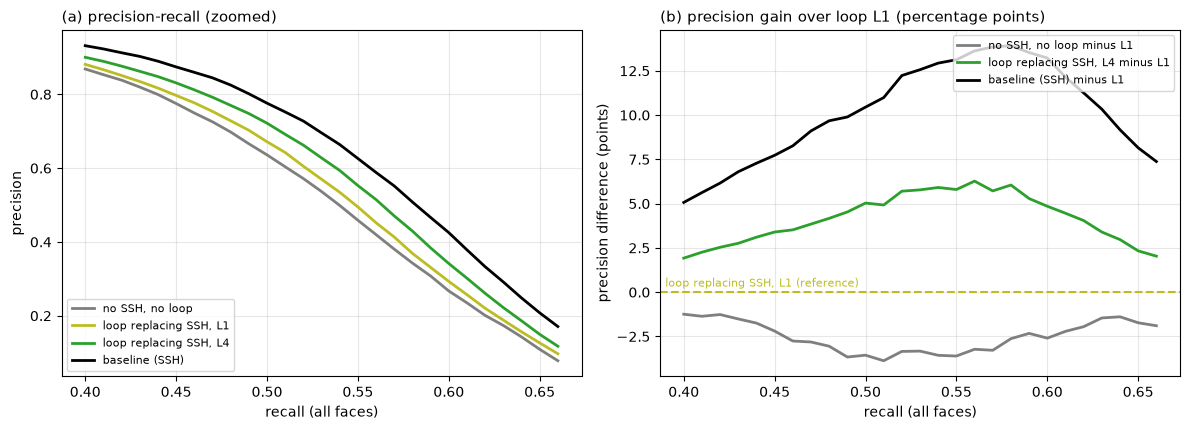

In [10]:

# =================== Figure B: precision-recall, curves + gain over L1 ===================
pr = pd.read_csv(rf"{ROOT}\outputs\pr_curve.csv").drop_duplicates(["tag", "recall"], keep="last")
print(pr.head(10))

PR_TAGS = {"cfg_mnet_nossh_L0_seed0": ("no SSH, no loop", "tab:gray"),
           "cfg_mnet_loop_nossh_L1_seed0": ("loop replacing SSH, L1", "tab:olive"),
           "cfg_mnet_loop_nossh_L4_seed0": ("loop replacing SSH, L4", "tab:green"),
           "cfg_mnet_L0_seed0": ("baseline (SSH)", "black")}
REF_PR = "cfg_mnet_loop_nossh_L1_seed0"
R_LO, R_HI = 0.40, 0.66

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for tag, (name, col) in PR_TAGS.items():
    g = pr[(pr.tag == tag) & pr.recall.between(R_LO, R_HI)].sort_values("recall")
    a1.plot(g.recall, g.precision, lw=2, color=col, label=name)
a1.set_title("(a) precision-recall (zoomed)", loc="left", fontsize=11)
a1.set_xlabel("recall (all faces)")
a1.set_ylabel("precision")
a1.grid(alpha=0.3)
a1.legend(fontsize=8, loc="lower left")

ref = pr[pr.tag == REF_PR].set_index("recall").precision
for tag, (name, col) in PR_TAGS.items():
    if tag == REF_PR:
        continue
    g = pr[(pr.tag == tag) & pr.recall.between(R_LO, R_HI)].set_index("recall").precision
    diff = (g - ref.reindex(g.index)) * 100                       # precision points above / below L1
    a2.plot(diff.index, diff.values, lw=2, color=col, label=f"{name} minus L1")
a2.axhline(0, color="tab:olive", lw=1.5, ls="--")
a2.annotate("loop replacing SSH, L1 (reference)", xy=(0.01, 0), xycoords=("axes fraction", "data"),
            xytext=(0, 4), textcoords="offset points", fontsize=8, color="tab:olive")
a2.set_title("(b) precision gain over loop L1 (percentage points)", loc="left", fontsize=11)
a2.set_xlabel("recall (all faces)")
a2.set_ylabel("precision difference (points)")
a2.grid(alpha=0.3)
a2.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
fig.savefig(rf"{ROOT}\outputs\fig_pr.pdf", bbox_inches="tight")
